**TENSORFLOW/KERAS MODEL**

In [2]:
# Importing all the necessary dependencies

import matplotlib.pyplot as plt

import pandas as pd

import numpy as np

import sklearn.model_selection
from sklearn.model_selection import train_test_split

import sklearn.preprocessing
from sklearn.preprocessing import StandardScaler

import sklearn.metrics
from sklearn.metrics import classification_report, confusion_matrix

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping

In [3]:
df = pd.read_csv('churn-bigml-80.csv')

In [4]:
df.head()

,State,Account length,Area code,International plan,Voice mail plan,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,Total eve charge,Total night minutes,Total night calls,Total night charge,Total intl minutes,Total intl calls,Total intl charge,Customer service calls,Churn
0,KS,128,415,No,Yes,25,265.1,110,45.07,197.4,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,OH,107,415,No,Yes,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,NJ,137,415,No,No,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,OH,84,408,Yes,No,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,OK,75,415,Yes,No,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False


In [5]:
df['International plan'] = df['International plan'].map({'Yes': 1, 'No': 0})
df['Voice mail plan'] = df['Voice mail plan'].map({'Yes': 1, 'No': 0})
df['Churn'] = df["Churn"].astype(int)

In [6]:
df.head()

,State,Account length,Area code,International plan,Voice mail plan,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,Total eve charge,Total night minutes,Total night calls,Total night charge,Total intl minutes,Total intl calls,Total intl charge,Customer service calls,Churn
0,KS,128,415,0,1,25,265.1,110,45.07,197.4,99,16.78,244.7,91,11.01,10.0,3,2.70,1,0
1,OH,107,415,0,1,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1,0
2,NJ,137,415,0,0,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0,0
3,OH,84,408,1,0,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2,0
4,OK,75,415,1,0,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3,0


In [7]:
# Picking the Features and the Target
X = df.drop(columns=['Churn', 'State', 'Area code'])
y = df['Churn']

In [8]:
# Train-Test-Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [9]:
# Scale your Features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [10]:
input_dim = X_train_scaled.shape[1]

In [11]:
# Choosing Parameters
model = models.Sequential(
    [
        layers.Input(shape=(input_dim,)),
        # First Hidden Layer
        layers.Dense(64, activation='relu'),
        layers.Dropout(0.3),
        # Second Hidden Layer
        layers.Dense(32, activation='relu'),
        layers.Dropout(0.2),
        #Output Layer
        layers.Dense(1, activation='sigmoid'),
    ] 
)

In [12]:
# Compiling the Features
model.compile(
    optimizer='adam', loss='binary_crossentropy', metrics=['accuracy']
)

In [13]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,265 (12.75 KB)

 Trainable params: 3,265 (12.75 KB)

 Non-trainable params: 0 (0.00 B)

In [14]:
# This is to avoid overfitting that may result from over-training the model
early_stop = EarlyStopping(
    monitor='val_loss', patience=5, restore_best_weights=True
)

In [15]:
# Training the Model
history = model.fit(
    X_train_scaled,
    y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop],
)

Epoch 1/30
54/54 ━━━━━━━━━━━━━━━━━━━━ 11s 22ms/step - accuracy: 0.8152 - loss: 0.4852 - val_accuracy: 0.8337 - val_loss: 0.4287
Epoch 2/30
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8639 - loss: 0.3743 - val_accuracy: 0.8384 - val_loss: 0.3790
Epoch 3/30
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8727 - loss: 0.3388 - val_accuracy: 0.8407 - val_loss: 0.3586
Epoch 4/30
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8704 - loss: 0.3269 - val_accuracy: 0.8454 - val_loss: 0.3467
Epoch 5/30
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8821 - loss: 0.3037 - val_accuracy: 0.8548 - val_loss: 0.3362
Epoch 6/30
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8804 - loss: 0.2916 - val_accuracy: 0.8548 - val_loss: 0.3303
Epoch 7/30
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8909 - loss: 0.2810 - val_accuracy: 0.8501 - val_loss: 0.3204
Epoch 8/30
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8950 - loss: 0.2716 - val_accuracy: 0.8712 - val_los

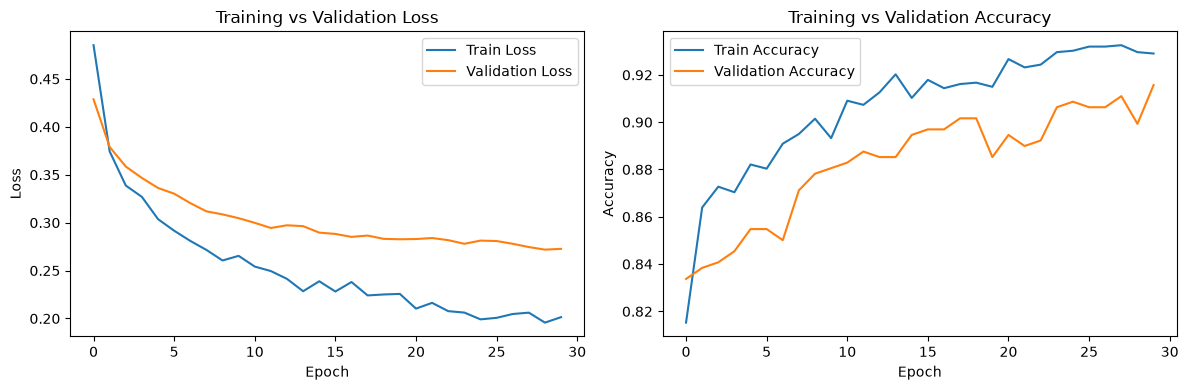

In [16]:
# Plots showing both Accuracy and Loss Validation Against the Trained Model

plt.figure(figsize=[12, 4])

# Loss Plot
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Train Loss' )
plt.plot(history.history['val_loss'], label='Validation Loss' )
plt.title('Training vs Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

# Accuracy Plot
plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Train Accuracy' )
plt.plot(history.history['val_accuracy'], label='Validation Accuracy' )
plt.title('Training vs Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

In [17]:
# Prediction Time: Predict probabilities
y_probs = model.predict(X_test_scaled)

17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step  


In [18]:
# Convertimng probabilities to binary predictions
y_pred = (y_probs >= 0.3).astype(int)

In [19]:
# Classification Report
print("\n----Classification Report----")
print(classification_report(y_test, y_pred))


----Classification Report----
              precision    recall  f1-score   support

           0       0.94      0.94      0.94       456
           1       0.63      0.64      0.64        78

    accuracy                           0.89       534
   macro avg       0.79      0.79      0.79       534
weighted avg       0.89      0.89      0.89       534

